In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cmcrameri import cm

# ------------------------------------------------------------
# Load mean IWC profile data
# ------------------------------------------------------------


In [2]:
bulk_data_df = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics/glaciations_with_bulk_data_V3_1_2007.parquet")
iwc_rel_df_1 = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics/iwc_rel_df_V3_1_2007.parquet")
mean_iwc_by_height_df = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics/mean_iwc_by_height_data_V3_1_2007.parquet")

In [3]:
iwc_rel_df_2 = pd.read_parquet("/nfs/ch4/wolke_scratch/dnikolo/GTE_Validation/DARDAR/Bulk/Bulk_statistics/iwc_rel_df_V3_1_2008.parquet")

In [4]:
iwc_rel_df = pd.concat([iwc_rel_df_1, iwc_rel_df_2], ignore_index=True)

In [5]:
(iwc_rel_df.avg_cth>0).value_counts

<bound method IndexOpsMixin.value_counts of 0       True
1       True
2       True
3       True
4       True
        ... 
3359    True
3360    True
3361    True
3362    True
3363    True
Name: avg_cth, Length: 3364, dtype: bool>

In [6]:
bulk_data_df.keys()

Index(['Cloud_ID', 'Time [m]', 'Magnitude', 'Glac_start_ind', 'Glac_peak_ind',
       'Linear', 'line_rmse', 'Rate_arr', 'Mean_glac_rate',
       'Glaciation time [h]', 'tracknumber', 'is_large_pix_cloud',
       'is_cot_valid_cloud', 'is_ctp_valid_cloud', 'is_liq', 'is_mix',
       'is_ice', 'max_water_frac', 'max_ice_fraction', 'avg_size[km]',
       'max_size[km]', 'min_size[km]', 'avg_size[px]', 'max_size[px]',
       'min_size[px]', 'track_start_time', 'track_length', 'avg_cot',
       'avg_ctp', 'avg_ctt', 'glaciation_start_time', 'glaciation_end_time',
       'avg_lat', 'avg_lon', 'start_ice_fraction', 'end_ice_fraction',
       'ice_frac_hist', 'cot_hist', 'cot_std_hist', 'cot_nan_frac_hist',
       'ctp_hist', 'ctp_std_hist', 'ctp_nan_frac_hist', 'ctt_hist',
       'ctt_std_hist', 'lat_hist', 'lon_hist', 'size_hist_km',
       'val_ice_frac_hist', 'val_ice_frac_std_hist', 'val_ice_frac_dev_hist',
       'val_pix_claas_if_hist', 'val_pix_claas_if_std_hist', 'val_cth_hist',
    

In [7]:
stats_by_rel_time.sev_cth

NameError: name 'stats_by_rel_time' is not defined

In [26]:
iwc_rel_df.keys()

Index(['Cloud_ID', 'rel_ind', 'rel_time_min', 'absolute_colocation_time',
       'iwc_profile', 'iwc_ct', 'bulk_height_profile_m', 'cloud_top_height_m',
       'cloud_top_temp_K', 'bulk_level_offset_top_m',
       'bulk_level_offset_bottom_m', 'bulk_level_offset_mid_m', 'Time [m]',
       'Magnitude', 'Glac_start_ind', 'Glac_peak_ind', 'Linear', 'line_rmse',
       'Rate_arr', 'Mean_glac_rate', 'Glaciation time [h]', 'tracknumber',
       'is_large_pix_cloud', 'is_cot_valid_cloud', 'is_ctp_valid_cloud',
       'is_liq', 'is_mix', 'is_ice', 'max_water_frac', 'max_ice_fraction',
       'avg_size[km]', 'max_size[km]', 'min_size[km]', 'avg_size[px]',
       'max_size[px]', 'min_size[px]', 'track_start_time', 'track_length',
       'avg_cot', 'avg_ctp', 'avg_ctt', 'glaciation_start_time',
       'glaciation_end_time', 'avg_lat', 'avg_lon', 'start_ice_fraction',
       'end_ice_fraction', 'ice_frac_hist', 'cot_hist', 'cot_std_hist',
       'cot_nan_frac_hist', 'ctp_hist', 'ctp_std_hist', 'ct

In [8]:
stats_by_rel_time = (
    iwc_rel_df
    .groupby("rel_ind")
    .agg(
        n_hits=("iwc_profile", "count"),

        mean_iwc_profile=(
            "iwc_profile",
            lambda profiles: np.nanmean(np.stack(profiles), axis=0),
        ),

        mean_bulk_height_profile_m=(
            "bulk_height_profile_m",
            lambda profiles: np.nanmean(np.stack(profiles), axis=0),
        ),

        bulk_offset_top_m=(
            "bulk_level_offset_top_m",
            lambda profiles: np.nanmean(np.stack(profiles), axis=0),
        ),

        bulk_offset_bottom_m=(
            "bulk_level_offset_bottom_m",
            lambda profiles: np.nanmean(np.stack(profiles), axis=0),
        ),

        dd_cth=(
            "cloud_top_height_m",
            "mean",
        ),

        sev_cth=(
            "avg_cth",
            "mean",
        ),

        dd_ctt=(
            "cloud_top_temp_K",
            "mean",
        ),

        mean_iwc_ct=(
            "iwc_ct",
            "mean",
        ),

        sev_ctt=(
            "avg_ctt",
            "mean",
        ),
        
        mean_area_km=(
            "avg_size[km]",
            "mean",
        ),
        
    )
    .reset_index()
)
stats_by_rel_time["rel_time_min"] = stats_by_rel_time["rel_ind"] * 15

/cluster/work/climate/dnikolo/dump/ipykernel_3417893/2001053864.py:9: RuntimeWarning: Mean of empty slice
  lambda profiles: np.nanmean(np.stack(profiles), axis=0),
/cluster/work/climate/dnikolo/dump/ipykernel_3417893/2001053864.py:14: RuntimeWarning: Mean of empty slice
  lambda profiles: np.nanmean(np.stack(profiles), axis=0),


In [9]:
stats_by_rel_time

,rel_ind,n_hits,mean_iwc_profile,mean_bulk_height_profile_m,bulk_offset_top_m,bulk_offset_bottom_m,dd_cth,sev_cth,dd_ctt,mean_iwc_ct,sev_ctt,mean_area_km,rel_time_min
0,-237,1,"[7.5360463e-06, 9.392705e-06, 1.0921682e-05, 1...","[5.3833957, 5.2597847, 5.137843, 5.0216613, 4....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.622109,4866.451039,233.978577,0.000004,240.180201,20116.688535,-3555
1,-235,1,"[1.923796e-05, 2.5789195e-05, 3.1331234e-05, 3...","[7.4441957, 7.3251233, 7.205397, 7.0857487, 6....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",7.685505,6584.499430,241.272949,0.000007,246.152981,156235.496425,-3525
2,-191,1,"[3.229844e-05, 2.8016402e-05, 2.4422423e-05, 1...","[3.5065553, 3.386195, 3.2698402, 3.1618223, 3....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",3.746890,3704.568968,256.481903,0.000032,258.371809,42926.886609,-2865
3,-178,2,"[3.170894e-05, 6.2820895e-05, 7.8904115e-05, 8...","[1.6474438, 1.538764, 1.5088353, 2.2303991, 2....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",1.888322,2033.451054,250.210442,0.000037,249.886662,242096.907311,-2670
4,-171,1,"[3.6298259e-06, 3.8822154e-06, 7.636698e-06, 8...","[0.9741952, 0.8790257, 0.8803947, 0.81685716, ...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",1.219781,1720.205315,260.507111,0.000007,258.157829,298164.903928,-2565
...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,133,1,"[3.913884e-06, 4.5248776e-06, 5.233309e-06, 6....","[6.6360483, 6.5214186, 6.401641, 6.2744126, 6....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",6.835588,6450.176940,245.149414,0.000003,246.133802,121647.131666,1995
222,135,1,"[1.0763274e-05, 1.3162429e-05, 1.5043827e-05, ...","[4.493422, 4.3605795, 4.2286267, 4.105889, 3.9...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",4.693939,5325.863517,242.173737,0.000005,240.698474,44023.674165,2025
223,144,1,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",NaN,3070.186964,NaN,NaN,268.340821,62996.533863,2160
224,161,1,"[2.6128524e-05, 3.81908e-05, 5.1112747e-05, 6....","[2.8843033, 2.7600226, 2.6453137, 2.5232015, 2...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",3.148143,3833.476650,244.388000,0.000015,241.237107,152614.256147,2415


In [10]:
bulk_data_df.bulk_level_offset_top_m

326       [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
383       [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
437       [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
469       [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
524       [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
                                ...                        
134376    [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
134380    [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
134512    [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
134563    [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
134599    [-240.0, -360.0, -480.0, -600.0, -720.0, -840....
Name: bulk_level_offset_top_m, Length: 1808, dtype: object

In [11]:
242.247587-273.15

-30.902412999999967

In [12]:
raw_df = pd.read_parquet("/cluster/work/climate/dnikolo/MSGI/development/iwc_rel_df_V3_1_2007.parquet")

In [13]:
raw_df

,Cloud_ID,rel_ind,rel_time_min,iwc_profile,iwc_ct,bulk_height_profile_km,cloud_top_height_km,cloud_top_temp_K,bulk_level_offset_top_m,bulk_level_offset_bottom_m,bulk_level_offset_mid_m
0,70032,-18,-270,"[2.158618e-06, 2.1748494e-06, 2.4971746e-06, 2...",0.000002,"[6.084497, 5.9561296, 5.9004436, 4.9431973, 4....",6.012133,240.739761,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
1,72095,35,525,"[0.00011846152, 0.00013470232, 0.00014699617, ...",0.000054,"[4.180037, 4.06028, 3.9409032, 3.7333317, 3.61...",4.420094,258.236023,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
2,73526,43,645,"[3.7624195e-06, 2.2079405e-06, 2.4431326e-06, ...",0.000001,"[2.8091538, 2.4287832, 2.3178222, 2.1761014, 2...",3.100846,256.385834,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
3,73526,82,1230,"[8.15021e-05, 0.00011599467, 0.0001784081, 0.0...",0.000184,"[2.2648573, 2.1440778, 2.1973572, 2.0808573, 1...",2.860517,257.866089,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
4,74600,-17,-255,"[2.5398856e-05, 2.7678829e-05, 3.135917e-05, 3...",0.000019,"[6.3253098, 6.209402, 6.085881, 5.968366, 5.84...",6.575131,256.105347,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
...,...,...,...,...,...,...,...,...,...,...,...
1774,3945587,-5,-75,"[2.063213e-06, 2.5378226e-06, 2.944727e-06, 3....",0.000002,"[8.507046, 8.387965, 8.271511, 8.154034, 8.034...",8.844634,232.125000,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
1775,3945597,-19,-285,"[5.537839e-06, 7.159543e-06, 8.927237e-06, 1.0...",0.000003,"[4.534437, 4.4145417, 4.3015833, 4.1815834, 4....",4.785823,240.683563,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
1776,3946485,-21,-315,"[9.3245135e-06, 1.2516345e-05, 1.540407e-05, 1...",0.000005,"[4.7329364, 4.602716, 4.495544, 4.3633037, 4.2...",5.019020,238.570984,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."
1777,3946835,-9,-135,"[8.981563e-06, 1.1038704e-05, 1.2445311e-05, 1...",0.000004,"[6.4913526, 6.36942, 6.250576, 6.1319737, 6.01...",6.721811,243.639206,"[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....","[-300.0, -420.0, -540.0, -660.0, -780.0, -900...."


(0.0, 1.342334861843039e-05)

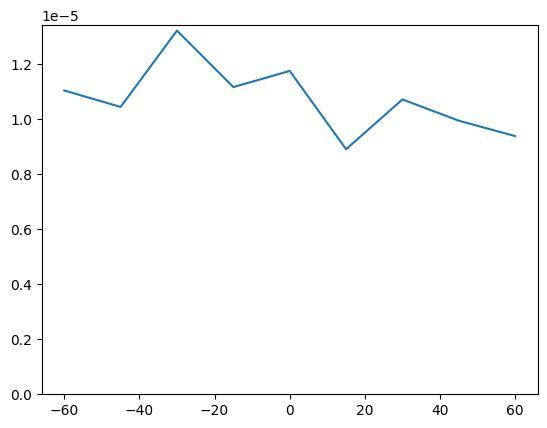

In [14]:
target_range = stats_by_rel_time[stats_by_rel_time["rel_ind"].isin(range(-4, +5))]
plt.plot(target_range["rel_time_min"],target_range["mean_iwc_ct"])
plt.ylim(0)

In [15]:
# DARDAR_DZ_M=60.0
# height_ranges = [[-240,-1200],[-1380,-2100]]
# BULK_LEVEL_OFFSETS_M=np.empty((1,2),dtype=np.float32)
# for range in height_ranges:
#     temp = np.arange(range[0],range[1]-DARDAR_DZ_M,-int(DARDAR_DZ_M*2),dtype=np.float32,)
#     BULK_LEVEL_OFFSETS_M = np.concatenate([BULK_LEVEL_OFFSETS_M,np.array(list(zip(temp[:-1],temp[1:])))],axis=0)
# BULK_LEVEL_OFFSETS_M = BULK_LEVEL_OFFSETS_M[1:]
# BULK_LEVEL_OFFSETS_M
# f" Levels below top: {BULK_LEVEL_OFFSETS_M[:,0]}"

In [16]:
stats_by_rel_time

,rel_ind,n_hits,mean_iwc_profile,mean_bulk_height_profile_m,bulk_offset_top_m,bulk_offset_bottom_m,dd_cth,sev_cth,dd_ctt,mean_iwc_ct,sev_ctt,mean_area_km,rel_time_min
0,-237,1,"[7.5360463e-06, 9.392705e-06, 1.0921682e-05, 1...","[5.3833957, 5.2597847, 5.137843, 5.0216613, 4....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.622109,4866.451039,233.978577,0.000004,240.180201,20116.688535,-3555
1,-235,1,"[1.923796e-05, 2.5789195e-05, 3.1331234e-05, 3...","[7.4441957, 7.3251233, 7.205397, 7.0857487, 6....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",7.685505,6584.499430,241.272949,0.000007,246.152981,156235.496425,-3525
2,-191,1,"[3.229844e-05, 2.8016402e-05, 2.4422423e-05, 1...","[3.5065553, 3.386195, 3.2698402, 3.1618223, 3....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",3.746890,3704.568968,256.481903,0.000032,258.371809,42926.886609,-2865
3,-178,2,"[3.170894e-05, 6.2820895e-05, 7.8904115e-05, 8...","[1.6474438, 1.538764, 1.5088353, 2.2303991, 2....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",1.888322,2033.451054,250.210442,0.000037,249.886662,242096.907311,-2670
4,-171,1,"[3.6298259e-06, 3.8822154e-06, 7.636698e-06, 8...","[0.9741952, 0.8790257, 0.8803947, 0.81685716, ...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",1.219781,1720.205315,260.507111,0.000007,258.157829,298164.903928,-2565
...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,133,1,"[3.913884e-06, 4.5248776e-06, 5.233309e-06, 6....","[6.6360483, 6.5214186, 6.401641, 6.2744126, 6....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",6.835588,6450.176940,245.149414,0.000003,246.133802,121647.131666,1995
222,135,1,"[1.0763274e-05, 1.3162429e-05, 1.5043827e-05, ...","[4.493422, 4.3605795, 4.2286267, 4.105889, 3.9...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",4.693939,5325.863517,242.173737,0.000005,240.698474,44023.674165,2025
223,144,1,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",NaN,3070.186964,NaN,NaN,268.340821,62996.533863,2160
224,161,1,"[2.6128524e-05, 3.81908e-05, 5.1112747e-05, 6....","[2.8843033, 2.7600226, 2.6453137, 2.5232015, 2...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",3.148143,3833.476650,244.388000,0.000015,241.237107,152614.256147,2415


In [17]:
# top=10
# lower_step=2
# n_height=70
# a = np.arange(-1140,-2100,-120,dtype=np.float32,)
# np.array(list(zip(a[:-1],a[1:])))
# for level, (top_offset_m, bottom_offset_m) in enumerate(BULK_LEVEL_OFFSETS_M):
#     start = int(round(abs(top_offset_m) / DARDAR_DZ_M))
#     stop = int(round(abs(bottom_offset_m) / DARDAR_DZ_M))

#     pair = [
#         top + lower_step * idx
#         for idx in range(start, stop)
#         if 0 <= top + lower_step * idx < n_height
#     ]
#     if (not pair) or (len(pair)!=2):
#         continue
#     print(pair)

In [18]:
import xarray as xr

In [19]:
dardar_data = xr.open_dataset("/nfs/ch4/wolke_scratch/dnikolo/DARDAR_data/DARDAR-CLOUD/V3_1/2008/2008_01_02/DARDAR-CLOUD_2008002042122_08939_V3-10.nc")

In [20]:
dardar_data["vis_optical_depth"]

<xarray.DataArray 'vis_optical_depth' (time: 37082)> Size: 148kB
[37082 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 297kB 2008-01-02T04:21:22.337890625 ... 20...
Attributes:
    units:        1
    long_name:    Optical Thickness forward model
    comment:      
    valid_range:  [ 0. 50.]

In [21]:
stats_by_rel_time[stats_by_rel_time["rel_ind"].isin(range(-4,5))]

,rel_ind,n_hits,mean_iwc_profile,mean_bulk_height_profile_m,bulk_offset_top_m,bulk_offset_bottom_m,dd_cth,sev_cth,dd_ctt,mean_iwc_ct,sev_ctt,mean_area_km,rel_time_min
123,-4,129,"[2.5713223e-05, 2.9501007e-05, 3.5442736e-05, ...","[5.74004, 5.5957747, 5.480219, 5.3608007, 5.25...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",6.015068,5830.245686,243.395978,0.000011,244.307932,14096.546274,-60
124,-3,112,"[1.9804453e-05, 2.4347868e-05, 2.8432069e-05, ...","[5.8358803, 5.7032824, 5.581083, 5.4607997, 5....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",6.110578,5790.199921,243.251161,0.000010,244.726614,17279.219818,-45
125,-2,127,"[2.5389905e-05, 3.2136817e-05, 3.865568e-05, 5...","[5.4576426, 5.372975, 5.2444077, 5.13187, 5.07...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.729947,5568.455118,244.785576,0.000013,246.950147,10660.846191,-30
126,-1,116,"[2.4097168e-05, 2.9962426e-05, 3.209986e-05, 3...","[5.496382, 5.372197, 5.248441, 5.1500306, 5.07...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.811417,5612.075330,243.255265,0.000011,245.676058,13659.320594,-15
127,0,102,"[2.618314e-05, 3.3364497e-05, 3.9520368e-05, 4...","[5.4845376, 5.340659, 5.1792426, 5.0627437, 4....","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.747864,5677.416550,241.700739,0.000012,243.572343,14480.109313,0
128,1,67,"[1.9637078e-05, 2.597036e-05, 3.1447384e-05, 3...","[4.9645486, 4.854737, 4.709592, 4.6231856, 4.5...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.287967,5289.763239,244.431081,0.000009,245.293889,15565.343859,15
129,2,64,"[2.1954036e-05, 2.7879205e-05, 3.4208606e-05, ...","[5.5865192, 5.55551, 5.3057756, 5.192377, 5.06...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.859834,5566.501211,240.969694,0.000011,243.554805,17545.974944,30
130,3,48,"[1.8862858e-05, 2.369871e-05, 2.8591485e-05, 3...","[5.0668154, 4.9447575, 4.820554, 4.705783, 4.6...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",5.345179,5215.011096,242.997653,0.000010,245.328253,18331.321424,45
131,4,38,"[2.2805405e-05, 3.1264222e-05, 3.871512e-05, 4...","[4.6255093, 4.489644, 4.367033, 4.2274084, 4.1...","[-240.0, -360.0, -480.0, -600.0, -720.0, -840....","[-360.0, -480.0, -600.0, -720.0, -840.0, -960....",4.896820,4882.034491,244.848478,0.000009,246.661931,17251.140913,60


In [22]:
mean_iwc_all = np.nanmean(
    np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
)
mean_iwc_all

4.632462e-05

In [23]:
all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
all_time_mean_by_level

NameError: name 'level_values' is not defined

In [ ]:
all_time_mean_by_level

{(-240.0, -360.0): 4.632462e-05,
 (-360.0, -480.0): 4.632462e-05,
 (-480.0, -600.0): 4.632462e-05,
 (-600.0, -720.0): 4.632462e-05,
 (-720.0, -840.0): 4.632462e-05,
 (-840.0, -960.0): 4.632462e-05,
 (-960.0, -1080.0): 4.632462e-05,
 (-1080.0, -1200.0): 4.632462e-05,
 (-1380.0, -1500.0): 4.632462e-05,
 (-1500.0, -1620.0): 4.632462e-05,
 (-1620.0, -1740.0): 4.632462e-05,
 (-1740.0, -1860.0): 4.632462e-05,
 (-1860.0, -1980.0): 4.632462e-05,
 (-1980.0, -2100.0): 4.632462e-05}

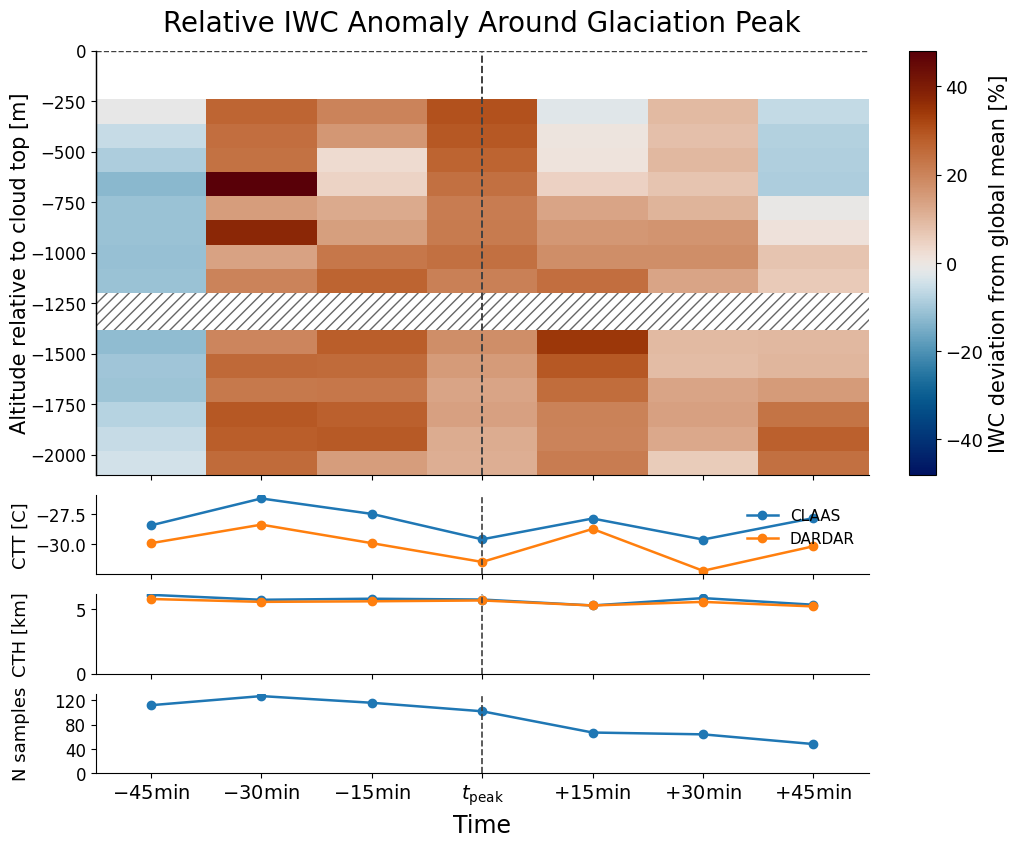

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import MaxNLocator
from cmcrameri import cm

# ------------------------------------------------------------
# Times to plot
# ------------------------------------------------------------
target_times = [ -45, -30, -15, 0, 15, 30, 45]

df_plot = (
    stats_by_rel_time[
        stats_by_rel_time["rel_time_min"].isin(target_times)
    ]
    .sort_values("rel_time_min")
    .copy()
)

missing = sorted(set(target_times) - set(df_plot["rel_time_min"]))
if missing:
    print(f"Warning: missing requested relative times: {missing}")

# ------------------------------------------------------------
# Compute all-time mean profile by actual vertical level
# ------------------------------------------------------------
level_values = {}

for _, row in stats_by_rel_time.iterrows():
    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    for t, b, val in zip(top[mask], bottom[mask], z[mask]):
        key = (float(t), float(b))
        level_values.setdefault(key, []).append(val)

all_time_mean_by_level = {
    key: np.nanmean(vals)
    for key, vals in level_values.items()
}
# mean_iwc_all = np.nanmean(
#     np.stack(stats_by_rel_time["mean_iwc_profile"].to_numpy())
# )
# all_time_mean_by_level = {
#     key: mean_iwc_all
#     for key, vals in level_values.items()
# }


# ------------------------------------------------------------
# Build anomaly records
# ------------------------------------------------------------
records = []

for _, row in df_plot.iterrows():
    rel_time = row["rel_time_min"]

    top = np.asarray(row["bulk_offset_top_m"], dtype=float)
    bottom = np.asarray(row["bulk_offset_bottom_m"], dtype=float)
    z = np.asarray(row["mean_iwc_profile"], dtype=float)

    n = min(len(top), len(bottom), len(z))
    top = top[:n]
    bottom = bottom[:n]
    z = z[:n]

    mask = (
        np.isfinite(top)
        & np.isfinite(bottom)
        & np.isfinite(z)
        & (z > 0)
    )

    top = top[mask]
    bottom = bottom[mask]
    z = z[mask]

    for t, b, val in zip(top, bottom, z):
        key = (float(t), float(b))
        mean_val = all_time_mean_by_level.get(key, np.nan)

        if np.isfinite(mean_val) and mean_val > 0:
            anomaly = 100 * (val - mean_val) / mean_val
        else:
            anomaly = np.nan

        records.append(
            {
                "rel_time_min": rel_time,
                "top": t,
                "bottom": b,
                "anomaly": anomaly,
            }
        )

anomaly_vals = np.asarray([
    r["anomaly"] for r in records
    if np.isfinite(r["anomaly"])
])

absmax = np.nanmax(np.abs(anomaly_vals))

norm = TwoSlopeNorm(
    vmin=-absmax,
    vcenter=0,
    vmax=absmax
)

cmap = cm.vik

# ------------------------------------------------------------
# Figure layout: heatmap + 3 shallow line plots + colorbar column
# ------------------------------------------------------------
fig = plt.figure(figsize=(10.5, 8.6))
fig.patch.set_alpha(0)

gs = GridSpec(
    nrows=4,
    ncols=2,
    width_ratios=[1, 0.035],
    height_ratios=[5.6, 1.05, 1.05, 1.05],
    hspace=0.12,
    wspace=0.10
)

ax = fig.add_subplot(gs[0, 0])
ax_ctt = fig.add_subplot(gs[1, 0], sharex=ax)
ax_cth = fig.add_subplot(gs[2, 0], sharex=ax)
ax_hits = fig.add_subplot(gs[3, 0], sharex=ax)

# dedicated colorbar axis, only next to the heatmap
cax = fig.add_subplot(gs[0, 1])

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.set_facecolor("none")

cax.set_facecolor("none")

# ------------------------------------------------------------
# Main heatmap
# ------------------------------------------------------------
x_width = 15.0

for rel_time in df_plot["rel_time_min"].values:
    row_records = [
        r for r in records
        if r["rel_time_min"] == rel_time
        and np.isfinite(r["anomaly"])
    ]

    if len(row_records) == 0:
        continue

    x_left = rel_time - x_width / 2

    row_records = sorted(row_records, key=lambda r: min(r["top"], r["bottom"]))

    for r in row_records:
        y_low = min(r["top"], r["bottom"])
        height = abs(r["bottom"] - r["top"])

        rect = Rectangle(
            (x_left, y_low),
            x_width,
            height,
            facecolor=cmap(norm(r["anomaly"])),
            edgecolor="none",
            hatch=None,
            zorder=1
        )
        ax.add_patch(rect)

    intervals = []

    for r in row_records:
        y0 = min(r["top"], r["bottom"])
        y1 = max(r["top"], r["bottom"])
        intervals.append((y0, y1))

    intervals = sorted(intervals, key=lambda p: p[0])

    for (prev_low, prev_high), (next_low, next_high) in zip(intervals[:-1], intervals[1:]):
        if next_low > prev_high and not np.isclose(next_low, prev_high):
            gap_low = prev_high
            gap_height = next_low - prev_high

            gap_rect = Rectangle(
                (x_left, gap_low),
                x_width,
                gap_height,
                facecolor="white",
                edgecolor="0.4",
                hatch="///",
                linewidth=0.0,
                zorder=2
            )
            ax.add_patch(gap_rect)

# ------------------------------------------------------------
# Colorbar
# ------------------------------------------------------------
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("IWC deviation from global mean [%]", fontsize=15)
cbar.ax.tick_params(labelsize=13)

# ------------------------------------------------------------
# Main axis styling
# ------------------------------------------------------------
ax.set_title(
    "Relative IWC Anomaly Around Glaciation Peak",
    fontsize=20,
    pad=14,
)

ax.set_ylabel("Altitude relative to cloud top [m]", fontsize=17)

all_tops = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_top_m"]
])

all_bottoms = np.concatenate([
    np.asarray(v, dtype=float)
    for v in df_plot["bulk_offset_bottom_m"]
])

ax.set_ylim(
    np.nanmin([all_tops.min(), all_bottoms.min()]),
    0
)

ax.axvline(
    0,
    linestyle="--",
    linewidth=1.4,
    color="0.25",
    zorder=4
)

ax.axhline(
    0,
    linestyle="--",
    linewidth=1.0,
    color="0.25",
    zorder=4
)

# Hide x tick labels on upper panels
plt.setp(ax.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Cloud top temperature line plot
# ------------------------------------------------------------
times = df_plot["rel_time_min"].to_numpy(dtype=float)

ax_ctt.plot(
    times,
    df_plot["sev_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="CLAAS"
)

ax_ctt.plot(
    times,
    df_plot["dd_ctt"].to_numpy(dtype=float) - 273.15,
    marker="o",
    linewidth=1.8,
    label="DARDAR"
)

ax_ctt.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_ctt.set_ylabel("CTT [C]", fontsize=13)
ax_ctt.tick_params(axis="y", labelsize=12)
ax_ctt.legend(
    frameon=False,
    fontsize=11,
    loc="upper right"
)

plt.setp(ax_ctt.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# Mean cloud top height line plot
# ------------------------------------------------------------
ax_cth.plot(
    times,
    df_plot["dd_cth"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)
ax_cth.plot(
    times,
    df_plot["sev_cth"].to_numpy(dtype=float)/1000,
    marker="o",
    linewidth=1.8
)

ax_cth.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_cth.set_ylabel("CTH [km]", fontsize=13)
ax_cth.tick_params(axis="y", labelsize=12)
ax_cth.set_ylim(0)
plt.setp(ax_cth.get_xticklabels(), visible=False)

# ------------------------------------------------------------
# n_hits line plot
# ------------------------------------------------------------
ax_hits.plot(
    times,
    df_plot["n_hits"].to_numpy(dtype=float),
    marker="o",
    linewidth=1.8
)

ax_hits.axvline(
    0,
    linestyle="--",
    linewidth=1.2,
    color="0.25"
)

ax_hits.set_ylabel("N samples", fontsize=13)
ax_hits.tick_params(axis="y", labelsize=12)
ax_hits.yaxis.set_major_locator(
    MaxNLocator(nbins=4, integer=True)
)
ax_hits.set_ylim(0)

# ------------------------------------------------------------
# Consistent y-axis label styling and alignment
# ------------------------------------------------------------
ylabel_fontsize = 13
ylabel_pad = 42

for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.yaxis.label.set_size(ylabel_fontsize)
    a.yaxis.labelpad = ylabel_pad
    a.yaxis.set_label_coords(-0.085, 0.5)
    a.tick_params(axis="y", labelsize=12)

# Make main heatmap label slightly larger only if desired
ax.yaxis.label.set_size(15)
# ------------------------------------------------------------
# Shared x-axis formatting
# ------------------------------------------------------------
ax_hits.set_xlim(
    min(target_times) - x_width / 2,
    max(target_times) + x_width / 2,
)

ax_hits.set_xlabel("Time", fontsize=17)

ax_hits.set_xticks(target_times)


ax_hits.set_xticklabels(
    [
        # r"$- 60\mathrm{min}$",
        r"$- 45\mathrm{min}$",
        r"$- 30\mathrm{min}$",
        r"$- 15\mathrm{min}$",
        r"$t_{\mathrm{peak}}$",
        r"$+ 15\mathrm{min}$",
        r"$+ 30\mathrm{min}$",
        r"$+ 45\mathrm{min}$",
        # r"$+ 60\mathrm{min}$",
    ],
    fontsize=14,
)

# ------------------------------------------------------------
# Clean style
# ------------------------------------------------------------
for a in [ax, ax_ctt, ax_cth, ax_hits]:
    a.spines["top"].set_visible(False)
    a.spines["right"].set_visible(False)
    a.spines["left"].set_zorder(10)
    a.spines["bottom"].set_zorder(10)

# redraw left axis line on heatmap, if patches cover it
ax.axvline(
    ax.get_xlim()[0],
    color="black",
    linewidth=1.0,
    zorder=10,
    clip_on=False
)

fig.subplots_adjust(
    left=0.10,
    right=0.90,
    top=0.94,
    bottom=0.10
)

plt.savefig(
    "relative_iwc_anomaly_heatmap_with_ctt_cth_nhits_panels.png",
    transparent=True,
    bbox_inches="tight",
    dpi=300,
)

plt.show()